# Artificial Intelligence Lab - LAB 05
## Experiment 5: Local Search (Hill Climbing & Simulated Annealing)
### Objectives:
1. **Continuous 1D Function Global Optimization**:
   - Find global maximum of $f(x) = \sin(x) + \sin(10x/3)$ for $x \in [0, 10]$.
   - Compare **Hill Climbing** vs. **Simulated Annealing**.
   - Visualize function landscape and step traces.
2. **8-Queens Problem Formulation**:
   - Objective function: Non-attacking queen pairs ($28 - \text{conflicts}$).
   - Compare **First-Choice Hill Climbing** vs. **Simulated Annealing**.

### 1. Part 1: Continuous Function Optimization Functions

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

def objective_function(x):
    return math.sin(x) + math.sin(10.0 * x / 3.0)

def hill_climbing_continuous(x_init=1.5, step_size=0.05, max_iter=200):
    current_x = x_init
    current_f = objective_function(current_x)
    history = [(current_x, current_f)]

    for _ in range(max_iter):
        cand_left = max(0.0, min(10.0, current_x - step_size))
        cand_right = max(0.0, min(10.0, current_x + step_size))

        f_left = objective_function(cand_left)
        f_right = objective_function(cand_right)

        if f_left > current_f and f_left >= f_right:
            current_x, current_f = cand_left, f_left
            history.append((current_x, current_f))
        elif f_right > current_f:
            current_x, current_f = cand_right, f_right
            history.append((current_x, current_f))
        else:
            break

    return current_x, current_f, history

def simulated_annealing_continuous(x_init=1.5, t_init=50.0, alpha=0.995, max_iter=2000):
    current_x = x_init
    current_f = objective_function(current_x)
    best_x, best_f = current_x, current_f
    history = [(current_x, current_f)]

    t = t_init
    for _ in range(max_iter):
        step = random.uniform(-4.0, 4.0)
        cand_x = max(0.0, min(10.0, current_x + step))
        cand_f = objective_function(cand_x)

        delta = cand_f - current_f

        if delta > 0 or math.exp(delta / max(t, 1e-8)) > random.random():
            current_x, current_f = cand_x, cand_f
            history.append((current_x, current_f))
            if current_f > best_f:
                best_x, best_f = current_x, current_f

        t *= alpha
        if t < 1e-4:
            break

    return best_x, best_f, history

### 2. Part 1: Optimization Results and Visual Comparison

Hill Climbing:       x = 2.3000, f(x) = 1.7282
Simulated Annealing: x = 7.9979, f(x) = 1.9887


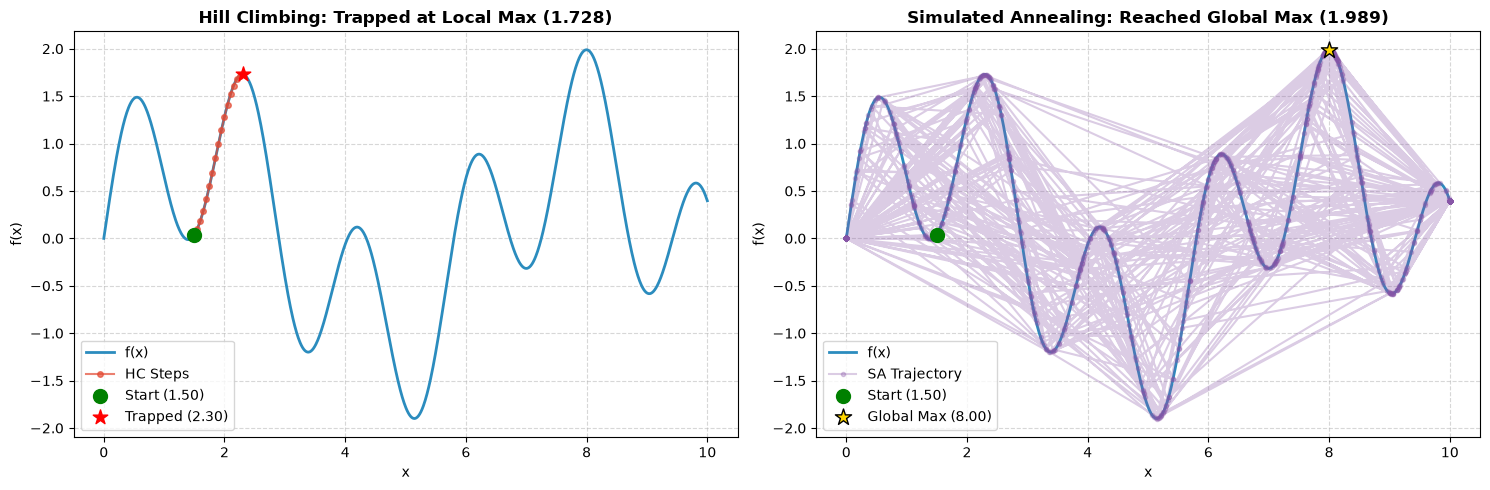

In [2]:
def visualize_continuous_optimization(hc_hist, sa_hist):
    x_vals = np.linspace(0, 10, 1000)
    y_vals = [objective_function(x) for x in x_vals]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    hc_xs, hc_ys = zip(*hc_hist)
    axes[0].plot(x_vals, y_vals, label='f(x)', color='#2b8cbe', linewidth=2)
    axes[0].plot(hc_xs, hc_ys, 'o-', color='#e34a33', markersize=4, alpha=0.7, label='HC Steps')
    axes[0].scatter([hc_xs[0]], [hc_ys[0]], color='green', s=100, zorder=5, label=f'Start ({hc_xs[0]:.2f})')
    axes[0].scatter([hc_xs[-1]], [hc_ys[-1]], color='red', s=120, marker='*', zorder=5, label=f'Trapped ({hc_xs[-1]:.2f})')
    axes[0].set_title(f"Hill Climbing: Trapped at Local Max ({hc_ys[-1]:.3f})", fontweight='bold')
    axes[0].set_xlabel("x")
    axes[0].set_ylabel("f(x)")
    axes[0].grid(True, linestyle='--', alpha=0.5)
    axes[0].legend()

    sa_xs, sa_ys = zip(*sa_hist)
    axes[1].plot(x_vals, y_vals, label='f(x)', color='#2b8cbe', linewidth=2)
    axes[1].plot(sa_xs, sa_ys, 'o-', color='#8856a7', markersize=3, alpha=0.3, label='SA Trajectory')
    axes[1].scatter([sa_xs[0]], [sa_ys[0]], color='green', s=100, zorder=5, label=f'Start ({sa_xs[0]:.2f})')
    best_idx = np.argmax(sa_ys)
    axes[1].scatter([sa_xs[best_idx]], [sa_ys[best_idx]], color='gold', s=150, marker='*', edgecolors='black', zorder=5, label=f'Global Max ({sa_xs[best_idx]:.2f})')
    axes[1].set_title(f"Simulated Annealing: Reached Global Max ({sa_ys[best_idx]:.3f})", fontweight='bold')
    axes[1].set_xlabel("x")
    axes[1].set_ylabel("f(x)")
    axes[1].grid(True, linestyle='--', alpha=0.5)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

random.seed(1)
hc_x, hc_f, hc_hist = hill_climbing_continuous(x_init=1.5)
sa_x, sa_f, sa_hist = simulated_annealing_continuous(x_init=1.5)
print(f"Hill Climbing:       x = {hc_x:.4f}, f(x) = {hc_f:.4f}")
print(f"Simulated Annealing: x = {sa_x:.4f}, f(x) = {sa_f:.4f}")
visualize_continuous_optimization(hc_hist, sa_hist)

### 3. Part 2: 8-Queens Problem Formulation & Algorithms

In [3]:
def get_8queens_score(state):
    conflicts = 0
    n = len(state)
    for i in range(n):
        for j in range(i + 1, n):
            if state[i] == state[j] or abs(state[i] - state[j]) == abs(i - j):
                conflicts += 1
    return 28 - conflicts

def get_random_neighbor_8queens(state):
    neighbor = list(state)
    col = random.randint(0, 7)
    available_rows = [r for r in range(8) if r != state[col]]
    neighbor[col] = random.choice(available_rows)
    return neighbor

def first_choice_hill_climbing_8queens(max_iter=1000, max_tries_per_step=100):
    current_state = [random.randint(0, 7) for _ in range(8)]
    current_score = get_8queens_score(current_state)
    score_history = [current_score]

    for step in range(max_iter):
        if current_score == 28:
            break

        found_better = False
        for _ in range(max_tries_per_step):
            neighbor = get_random_neighbor_8queens(current_state)
            score = get_8queens_score(neighbor)
            if score > current_score:
                current_state = neighbor
                current_score = score
                score_history.append(current_score)
                found_better = True
                break

        if not found_better:
            break

    return current_state, current_score, score_history

def simulated_annealing_8queens(t_init=20.0, alpha=0.995, max_iter=5000):
    current_state = [random.randint(0, 7) for _ in range(8)]
    current_score = get_8queens_score(current_state)
    best_state = list(current_state)
    best_score = current_score
    score_history = [current_score]

    t = t_init
    for _ in range(max_iter):
        if best_score == 28:
            break

        neighbor = get_random_neighbor_8queens(current_state)
        cand_score = get_8queens_score(neighbor)
        delta = cand_score - current_score

        if delta > 0 or math.exp(delta / max(t, 1e-8)) > random.random():
            current_state = neighbor
            current_score = cand_score
            score_history.append(current_score)
            if current_score > best_score:
                best_state = list(current_state)
                best_score = current_score

        t *= alpha
        if t < 1e-4:
            break

    return best_state, best_score, score_history

def print_8queens_board(state):
    n = len(state)
    print("  +-" + "--" * n + "+")
    for r in range(n):
        row_str = f"{8 - r} | "
        for c in range(n):
            row_str += "Q " if state[c] == r else ". "
        row_str += "|"
        print(row_str)
    print("  +-" + "--" * n + "+")
    print("    A B C D E F G H")
    print(f"Non-attacking pairs: {get_8queens_score(state)} / 28 (Conflicts: {28 - get_8queens_score(state)})\n")

### 4. Part 2: Running 8-Queens Local Search Algorithms

In [4]:
random.seed(101)
fc_state, fc_score, fc_hist = first_choice_hill_climbing_8queens()
sa_state, sa_score, sa_hist = simulated_annealing_8queens()

print("--- First-Choice Hill Climbing ---")
print_8queens_board(fc_state)

print("--- Simulated Annealing ---")
print_8queens_board(sa_state)

--- First-Choice Hill Climbing ---
  +-----------------+
8 | . . . Q . . . . |
7 | . . . . Q . . . |
6 | Q . . . . . . . |
5 | . . . . . . . . |
4 | . . . . . . Q . |
3 | . Q . . . . . . |
2 | . . . . . Q . Q |
1 | . . Q . . . . . |
  +-----------------+
    A B C D E F G H
Non-attacking pairs: 26 / 28 (Conflicts: 2)

--- Simulated Annealing ---
  +-----------------+
8 | . . . Q . . . . |
7 | . . . . . . Q . |
6 | . . Q . . . . . |
5 | . . . . . . . Q |
4 | . Q . . . . . . |
3 | . . . . Q . . . |
2 | Q . . . . . . . |
1 | . . . . . Q . . |
  +-----------------+
    A B C D E F G H
Non-attacking pairs: 28 / 28 (Conflicts: 0)

